<a href="https://colab.research.google.com/github/Hyunkio/Linear_Algebra/blob/main/TIETransformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000        # 그림판 크기
LEN = 100         # 처음 사각형의 크기

In [2]:
# 동차좌표로 바꿔 행렬을 곱하고 2차원으로 되돌림: q = m p
def transform(p, m):
    hp = np.array([p[0], p[1], 1.0])

    q = np.dot(m, hp)

    q = np.array([q[0], q[1]])
    return q


# 이동: T(dx, dy)
def translate(p, dx, dy):
    m = np.array([[1.0, 0.0, dx],
                  [0.0, 1.0, dy],
                  [0.0, 0.0, 1.0]])
    return transform(p, m)


# 회전: R(theta)
def rotate(p, theta):
    c = np.cos(theta)
    s = np.sin(theta)
    m = np.array([[c,  -s,  0.0],
                  [s,   c,  0.0],
                  [0.0, 0.0, 1.0]])
    return transform(p, m)


# 크기: S(sx, sy)
def scale(p, sx, sy):
    m = np.array([[sx,  0.0, 0.0],
                  [0.0, sy,  0.0],
                  [0.0, 0.0, 1.0]])
    return transform(p, m)


# x축 방향 기울기: Shx(sx)
def shear_x(p, sx):
    m = np.array([[1.0, sx,  0.0],
                  [0.0, 1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    return transform(p, m)


# y축 방향 기울기: Shy(sy)
def shear_y(p, sy):
    m = np.array([[1.0, 0.0, 0.0],
                  [sy,  1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    return transform(p, m)


# x축 반전
def reflect_x(p):
    m = np.array([[1.0,  0.0, 0.0],
                  [0.0, -1.0, 0.0],
                  [0.0,  0.0, 1.0]])
    return transform(p, m)


# y축 반전: Rfy
def reflect_y(p):
    m = np.array([[-1.0, 0.0, 0.0],
                  [ 0.0, 1.0, 0.0],
                  [ 0.0, 0.0, 1.0]])
    return transform(p, m)


# 원점 반전
def reflect_origin(p):
    m = np.array([[-1.0,  0.0, 0.0],
                  [ 0.0, -1.0, 0.0],
                  [ 0.0,  0.0, 1.0]])
    return transform(p, m)


# y=x 반전
def reflect_xy(p):
    m = np.array([[0.0, 1.0, 0.0],
                  [1.0, 0.0, 0.0],
                  [0.0, 0.0, 1.0]])
    return transform(p, m)


# 사각형의 모든 꼭짓점에 같은 변환 적용
def transform_rect(rect, f, *args):
    return [f(p, *args) for p in rect]

In [3]:
# 변환 함수 결과 확인
p = np.array([100.0, 50.0])

checks = [
    ("translate(p, 30, -20)", translate(p, 30, -20),   [130,   30]),
    ("rotate(p, pi/2)",       rotate(p, np.pi/2),      [-50,  100]),
    ("scale(p, 2, 3)",        scale(p, 2, 3),          [200,  150]),
    ("shear_x(p, 1)",         shear_x(p, 1),           [150,   50]),
    ("shear_y(p, 1)",         shear_y(p, 1),           [100,  150]),
    ("reflect_x(p)",          reflect_x(p),            [100,  -50]),
    ("reflect_y(p)",          reflect_y(p),            [-100,  50]),
    ("reflect_origin(p)",     reflect_origin(p),       [-100, -50]),
    ("reflect_xy(p)",         reflect_xy(p),           [50,   100]),
]

for name, result, expected in checks:
    ok = "OK" if np.allclose(result, expected) else "틀림"
    print("%-22s = (%7.1f, %7.1f)   [%s]" % (name, result[0], result[1], ok))

translate(p, 30, -20)  = (  130.0,    30.0)   [OK]
rotate(p, pi/2)        = (  -50.0,   100.0)   [OK]
scale(p, 2, 3)         = (  200.0,   150.0)   [OK]
shear_x(p, 1)          = (  150.0,    50.0)   [OK]
shear_y(p, 1)          = (  100.0,   150.0)   [OK]
reflect_x(p)           = (  100.0,   -50.0)   [OK]
reflect_y(p)           = ( -100.0,    50.0)   [OK]
reflect_origin(p)      = ( -100.0,   -50.0)   [OK]
reflect_xy(p)          = (   50.0,   100.0)   [OK]


In [4]:
def draw_axis(ax):
    ax.axhline(0, color='black', alpha=0.3)
    ax.axvline(0, color='black', alpha=0.3)
    ax.set_xlim(-INF, INF)
    ax.set_ylim(-INF, INF)
    ax.set_aspect('equal')


def draw_rectangle(ax, p1, p2, p3, p4):
    my_polygon = Polygon([p1, p2, p3, p4])
    ax.add_patch(my_polygon)

In [5]:
# 중앙 조종석: 원점 중심의 마름모
def draw_cockpit(ax, p1, p2, p3, p4):
    q = [p1, p2, p3, p4]

    # 1. 원점으로 이동
    q = transform_rect(q, translate, -LEN/2, -LEN/2)

    # 2. 5배 확대
    s = 5
    q = transform_rect(q, scale, s, s)

    # 3. 45도 회전
    q = transform_rect(q, rotate, np.pi/4)

    draw_rectangle(ax, *q)

In [6]:
# 날개축: 위아래 빔 2개 (왼쪽은 조종사 기준이라 화면 오른쪽에 그려짐)
def make_arm(p1, p2, p3, p4):
    upper = [p1, p2, p3, p4]

    # 1. 긴 막대로 늘리기
    upper = transform_rect(upper, scale, 6.1, 0.8)

    # 2. 두께 중심을 x축에 맞추기
    upper = transform_rect(upper, translate, 0, -40)

    # 3. 바깥쪽으로 갈수록 내려가게 기울이기
    upper = transform_rect(upper, shear_y, -150/610)

    # 4. 조종석과 날개 사이로 이동
    upper = transform_rect(upper, translate, 150, 150)

    # 아래쪽 빔은 위쪽 빔을 x축 반전
    lower = transform_rect(upper, reflect_x)

    return [upper, lower]


def draw_left_arm(ax, p1, p2, p3, p4):
    for rect in make_arm(p1, p2, p3, p4):
        draw_rectangle(ax, *rect)


# 오른쪽 날개축은 왼쪽 날개축을 y축 반전
def draw_right_arm(ax, p1, p2, p3, p4):
    for rect in make_arm(p1, p2, p3, p4):
        draw_rectangle(ax, *transform_rect(rect, reflect_y))

In [7]:
# 날개: 세로판 + 위쪽 끝 + 아래쪽 끝
def make_wing(p1, p2, p3, p4):
    # 세로판
    body = [p1, p2, p3, p4]
    body = transform_rect(body, scale, 1, 8)
    body = transform_rect(body, translate, 750, -400)

    # 위쪽 끝: 바깥쪽으로 갈수록 올라가는 평행사변형
    top = [p1, p2, p3, p4]
    top = transform_rect(top, scale, 1, 2)
    top = transform_rect(top, shear_y, 2)
    top = transform_rect(top, translate, 750, 200)

    # 아래쪽 끝은 위쪽 끝을 x축 반전
    bottom = transform_rect(top, reflect_x)

    return [body, top, bottom]


def draw_left_wing(ax, p1, p2, p3, p4):
    for rect in make_wing(p1, p2, p3, p4):
        draw_rectangle(ax, *rect)


# 오른쪽 날개는 왼쪽 날개를 y축 반전
def draw_right_wing(ax, p1, p2, p3, p4):
    for rect in make_wing(p1, p2, p3, p4):
        draw_rectangle(ax, *transform_rect(rect, reflect_y))

In [8]:
def draw_object(ax):
    # 처음 사각형의 네 꼭짓점
    p1 = np.array([0, 0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])

    draw_cockpit(ax, p1, p2, p3, p4)

    draw_left_arm(ax, p1, p2, p3, p4)

    draw_left_wing(ax, p1, p2, p3, p4)

    draw_right_arm(ax, p1, p2, p3, p4)

    draw_right_wing(ax, p1, p2, p3, p4)

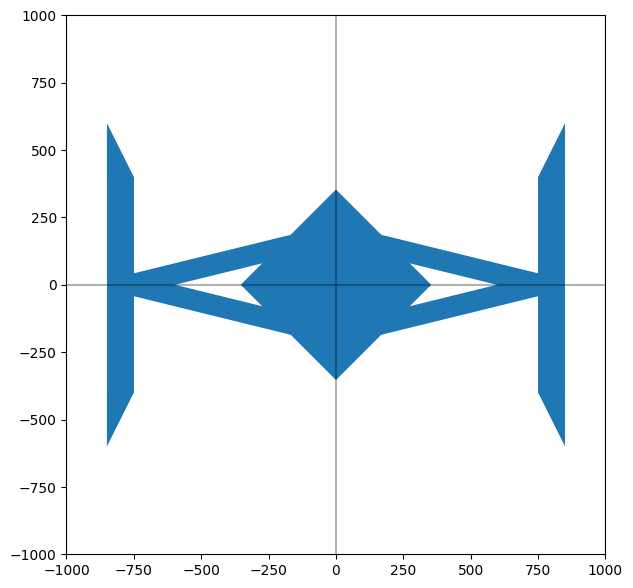

In [9]:
fig, ax = plt.subplots(figsize=(7,7))

draw_axis(ax)

draw_object(ax)

plt.show()